# Experiment 4 — Neural Network Classifier and Backpropagation

This experiment follows the lecture on **neural classification and backpropagation** and applies each idea to our task.

| Lecture topic | Section |
|---|---|
| Intrinsic word vector evaluation (analogies, WordSim353) | 4A |
| Computation graphs, forward/backward pass, node intuitions | 4B |
| Neural classifier $h = f(Wx+b)$, $s = u^Th$; gradients by hand | 4C |
| Checking hand-derived gradients | 4D |
| Non-linearities (linear, sigmoid, tanh, ReLU, Leaky ReLU, GELU); cross-entropy; SGD | 4E |
| "θ includes the word vectors too": learning the representations | 4F |

Everything is implemented **from scratch in NumPy** — no deep learning framework — so every gradient in the network is one we derive ourselves.
The classifier uses the same group-aware `train_idx` / `test_idx` split as Experiments 1–3 (`src/data.py`), so results are directly comparable.

*Run notebook 03 first: section 4G reads its results from `results/`.*

> **Note:** in the original combined notebook, the cross-validation loops in Experiment 3 reused the name `train_idx`, so this experiment was trained on the last CV fold instead of the shared training split, and that fold overlaps the test set. The test-F1 numbers quoted in the *Reading* and *Summary* cells below come from that run and need to be updated after re-running.

In [1]:
# 0. Make the shared `src` package importable (works from the repo root or from notebooks/)

import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

In [2]:
# Setup: imports, data, shared split, embeddings from Experiment 3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from gensim.models import Word2Vec
import gensim.downloader as api

from sklearn.metrics import accuracy_score, f1_score

from src.data import RANDOM_STATE, load_all, load_table, save_table
from src.embeddings import tokenize_text

main_df, groups, real_df, external_synthetic_df, train_idx, test_idx = load_all()
print("Training examples:", len(train_idx), "| Test examples:", len(test_idx))

# Pretrained GloVe (cached by gensim after the first download)
glove_model = api.load("glove-wiki-gigaword-100")

# Word2Vec on the full main dataset — identical settings to Experiment 3
full_w2v = Word2Vec(
    sentences=[tokenize_text(t) for t in main_df["text"]],
    vector_size=100, window=5, min_count=1, workers=1,
    sg=1, negative=5, epochs=100, seed=RANDOM_STATE
)

Training examples: 1881 | Test examples: 468


In [3]:
# Results from Experiment 3 (used in 4E and 4G)

def get_value(table, metric):
    return table.loc[
        table["Metric"] == metric,
        "Value"
    ].iloc[0]

glove_binary_metrics = load_table("exp3_glove_binary_metrics")
comparison_test = load_table("exp3_comparison_test")
comparison_external = load_table("exp3_comparison_external")

## Experiment 4A — Intrinsic evaluation of our word vectors

Experiment 3 evaluated embeddings **extrinsically** (by classification performance). The lecture also describes **intrinsic** evaluation:

- **Word analogies** $a:b :: c:?$ — find $d = \arg\max_i \frac{(x_b - x_a + x_c)^T x_i}{\lVert x_b - x_a + x_c \rVert}$, discarding the input words from the search.
- **Similarity correlation** — Spearman correlation between cosine similarity and human ratings on **WordSim353**.

We compare pretrained GloVe with the Word2Vec model trained on our project corpus (`full_w2v`, from Experiment 3). Both test files ship with `gensim`.

In [4]:
# 4A.1 Word analogies (gensim's most_similar excludes the input words, as in the lecture)

from gensim.test.utils import datapath

analogy_examples = [
    ("man", "woman", "king"),
    ("paris", "france", "tokyo"),
    ("good", "better", "bad"),
    ("buy", "bought", "sell"),
]

def solve_analogy(kv, a, b, c):
    if not all(w in kv for w in (a, b, c)):
        return "— (word missing)"
    word, score = kv.most_similar(positive=[b, c], negative=[a], topn=1)[0]
    return f"{word} ({score:.2f})"

analogy_rows = []
for a, b, c in analogy_examples:
    analogy_rows.append({
        "analogy": f"{a} : {b} :: {c} : ?",
        "GloVe (6B tokens)": solve_analogy(glove_model, a, b, c),
        "Word2Vec (project corpus)": solve_analogy(full_w2v.wv, a, b, c),
    })
display(pd.DataFrame(analogy_rows))

,analogy,GloVe (6B tokens),Word2Vec (project corpus)
0,man : woman :: king : ?,queen (0.77),— (word missing)
1,paris : france :: tokyo : ?,japan (0.89),— (word missing)
2,good : better :: bad : ?,worse (0.84),— (word missing)
3,buy : bought :: sell : ?,sold (0.92),practices (0.51)


In [5]:
# 4A.2 Benchmark scores: WordSim353 (similarity) and Google analogy questions

def intrinsic_scores(kv, name):
    pearson, spearman, oov_ratio = kv.evaluate_word_pairs(datapath("wordsim353.tsv"))
    analogy_acc, sections = kv.evaluate_word_analogies(
        datapath("questions-words.txt"), restrict_vocab=100000
    )
    total = sections[-1]
    n_answered = len(total["correct"]) + len(total["incorrect"])
    return {
        "Embedding": name,
        "Vocabulary": len(kv),
        "WordSim353 Spearman": spearman.statistic if hasattr(spearman, "statistic") else spearman[0],
        "WordSim353 pairs OOV %": oov_ratio,
        "Analogy accuracy": analogy_acc,
        "Analogy questions answerable": n_answered,
    }

intrinsic_table = pd.DataFrame([
    intrinsic_scores(glove_model, "GloVe (6B tokens)"),
    intrinsic_scores(full_w2v.wv, "Word2Vec (project corpus)"),
])
display(intrinsic_table.style.format({
    "WordSim353 Spearman": "{:.3f}",
    "WordSim353 pairs OOV %": "{:.1f}",
    "Analogy accuracy": "{:.3f}",
}))

,Embedding,Vocabulary,WordSim353 Spearman,WordSim353 pairs OOV %,Analogy accuracy,Analogy questions answerable
0,GloVe (6B tokens),400000,0.533,0.0,0.639,19230
1,Word2Vec (project corpus),3877,0.158,85.3,0.018,273


In [6]:
# 4A.3 Domain-specific neighbours: what does each embedding consider similar to persuasion cues?

cue_words = ["hurry", "only", "limited", "bought", "thanks", "left"]

def neighbours(kv, word, topn=5):
    if word not in kv:
        return "— (missing)"
    return ", ".join(w for w, _ in kv.most_similar(word, topn=topn))

display(pd.DataFrame({
    "word": cue_words,
    "GloVe neighbours": [neighbours(glove_model, w) for w in cue_words],
    "Project Word2Vec neighbours": [neighbours(full_w2v.wv, w) for w in cue_words],
}))

,word,GloVe neighbours,Project Word2Vec neighbours
0,hurry,"'ll, wait, hesitate, go, afraid","claimed, 894, 803, yards, left"
1,only,"one, it, but, same, though","left, stock, yards, quantity, yours"
2,limited,"restricted, addition, provided, extended, alth...","matching, grab, le, time, pair"
3,bought,"sold, purchased, sell, buy, acquired","buffalo, malaysia, rebecca, mini, sateen"
4,thanks,"despite, success, coming, good, strong","measured, coupons, despise, nah, saving"
5,left,"back, leaving, off, came, went","stock, yards, 1.75, inventory, warning"


**Reading 4A.** GloVe solves classic analogies and correlates with human similarity judgments, because it was trained on billions of tokens. Our project Word2Vec has a tiny vocabulary, cannot answer most benchmark questions, and its similarities are not human-like.
Its neighbours, however, are **domain-specific**: they reflect the templates of shop UI text. *only* and *left* are close to *stock* and *quantity* ("Only 3 left in stock"), *hurry* is close to *claimed* and numbers ("Hurry! 894 claimed"), and *bought* is close to place and person names, because activity notifications read "Rebecca from Malaysia just bought…". This is consistent with Experiment 3: weak intrinsic quality, but competitive extrinsic performance within the dark-patterns domain.
The lecture's warning also applies: intrinsic tests measure *linear* structure; information can be present but not linear, which is one motivation for a non-linear classifier (4C–4E).

## Experiment 4B — Backpropagation on a computation graph

Before the full network, we reproduce the lecture example
$$f(x,y,z) = (x+y)\,\max(y,z), \qquad x=1,\; y=2,\; z=0$$
with a minimal **automatic differentiation** engine. Each node knows (1) how to compute its output in the forward pass and (2) how to turn the upstream gradient into downstream gradients:
**[downstream gradient] = [upstream gradient] × [local gradient]**.

Backprop visits the nodes in reverse topological order, starting with output gradient 1, and **gradients sum at outward branches** (here `y` feeds both `+` and `max`).

In [7]:
# 4B.1 A minimal autograd engine (forward + backward per node, reverse topological order)

class Value:
    def __init__(self, data, parents=(), op="", label=""):
        self.data = data
        self.grad = 0.0
        self._parents = parents
        self._backward = lambda: None
        self.op, self.label = op, label

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():                       # + distributes the upstream gradient
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():                       # * switches the inputs
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward
        return out

    def max(self, other):
        out = Value(max(self.data, other.data), (self, other), "max")
        def _backward():                       # max routes the gradient to the larger input
            self.grad += out.grad * float(self.data >= other.data)
            other.grad += out.grad * float(other.data > self.data)
        out._backward = _backward
        return out

    def backward(self):
        order, seen = [], set()
        def visit(node):                       # topological sort
            if node not in seen:
                seen.add(node)
                for p in node._parents:
                    visit(p)
                order.append(node)
        visit(self)
        self.grad = 1.0                        # initialise output gradient = 1
        for node in reversed(order):           # visit nodes in reverse order
            node._backward()

x, y, z = Value(1.0, label="x"), Value(2.0, label="y"), Value(0.0, label="z")
a = x + y
b = y.max(z)
f = a * b
f.backward()

print(f"forward:  a = x+y = {a.data},  b = max(y,z) = {b.data},  f = a*b = {f.data}")
print(f"backward: df/da = {a.grad},  df/db = {b.grad}")
print(f"          df/dx = {x.grad},  df/dy = {y.grad} (= 2 via '+' + 3 via 'max'),  df/dz = {z.grad}")

forward:  a = x+y = 3.0,  b = max(y,z) = 2.0,  f = a*b = 6.0
backward: df/da = 2.0,  df/db = 3.0
          df/dx = 2.0,  df/dy = 5.0 (= 2 via '+' + 3 via 'max'),  df/dz = 0.0


In [8]:
# 4B.2 Check against numerical derivatives: (f(v + eps) - f(v - eps)) / 2eps

def f_scalar(x, y, z):
    return (x + y) * max(y, z)

eps = 1e-6
numeric = {
    "x": (f_scalar(1 + eps, 2, 0) - f_scalar(1 - eps, 2, 0)) / (2 * eps),
    "y": (f_scalar(1, 2 + eps, 0) - f_scalar(1, 2 - eps, 0)) / (2 * eps),
    "z": (f_scalar(1, 2, 0 + eps) - f_scalar(1, 2, 0 - eps)) / (2 * eps),
}
display(pd.DataFrame({
    "backprop": {"x": x.grad, "y": y.grad, "z": z.grad},
    "numerical": numeric,
}))

,backprop,numerical
x,2.0,2.0
y,5.0,5.0
z,0.0,0.0


## Experiment 4C — A one-hidden-layer neural classifier, gradients by hand

The lecture's NER model classifies a centre word from a *window* of word vectors. Our task is sentence-level, so the input is the **average of the word vectors** of the text, looked up from an embedding matrix $L$ (the "embedding layer" $x = Le$):

$$
x = \frac{1}{n}\sum_{t=1}^{n} L_{w_t}, \qquad
z = Wx + b, \qquad
h = f(z), \qquad
s = u^T h, \qquad
p = \sigma(s)
$$

with binary **cross-entropy** loss $J = -\left[y\log p + (1-y)\log(1-p)\right]$.

**Gradients (shape convention).** Following the lecture — break into simple pieces, apply the chain rule, reuse the upstream gradient:

| Quantity | Gradient | Note |
|---|---|---|
| $\partial J / \partial s$ | $p - y$ | sigmoid + cross-entropy simplify |
| $\partial J / \partial u$ | $(p-y)\, h$ | |
| $\delta = \partial J / \partial z$ | $(p-y)\, u \circ f'(z)$ | the **error signal**, same shape as $z$ |
| $\partial J / \partial W$ | $\delta\, x^T$ | outer product: upstream error × local input |
| $\partial J / \partial b$ | $\delta$ | |
| $\partial J / \partial x$ | $W^T \delta$ | passed further down |
| $\partial J / \partial L_{w}$ | $\frac{1}{n}\,W^T\delta$ for every word $w$ in the text | averaging is a "+" node: it **distributes** the gradient |

For a mini-batch, rows are examples, so $\partial J/\partial W = \delta^T X$ sums the outer products over the batch.

The derivatives of the non-linearities from the lecture:

| $f$ | $f(z)$ | $f'(z)$ |
|---|---|---|
| linear (none) | $z$ | $1$ |
| logistic | $\sigma(z)$ | $\sigma(z)(1-\sigma(z))$ |
| tanh | $\tanh(z)$ | $1-\tanh^2(z)$ |
| ReLU | $\max(z,0)$ | $\mathbb{1}[z>0]$ |
| Leaky ReLU | $\max(z, 0.01z)$ | $1$ or $0.01$ |
| GELU (approx.) | $z\,\sigma(1.702z)$ | $\sigma(1.702z) + 1.702\,z\,\sigma(1.702z)(1-\sigma(1.702z))$ |

In [9]:
# 4C.1 Vocabulary, embedding matrix initialised from GloVe, averaging matrices

import scipy.sparse as sp

nn_train_texts = main_df["text"].iloc[train_idx]
nn_test_texts = main_df["text"].iloc[test_idx]
y_nn_train = main_df["manipulative"].iloc[train_idx].to_numpy()
y_nn_test = main_df["manipulative"].iloc[test_idx].to_numpy()

# vocabulary from the training texts only (no test leakage)
nn_vocab = {}
for text in nn_train_texts:
    for word in tokenize_text(text):
        nn_vocab.setdefault(word, len(nn_vocab))
nn_index_to_word = np.array(list(nn_vocab))

EMB_DIM = glove_model.vector_size
L_init = np.zeros((len(nn_vocab), EMB_DIM))
for word, i in nn_vocab.items():
    if word in glove_model:
        L_init[i] = glove_model[word]        # words GloVe lacks start at zero and can be learned in 4F

def averaging_matrix(texts):
    # Sparse matrix A with A[i, w] = 1/n_i if word w occurs in text i, so X = A @ L
    rows, cols, vals = [], [], []
    for r, text in enumerate(texts):
        ids = [nn_vocab[w] for w in tokenize_text(text) if w in nn_vocab]
        for i in ids:
            rows.append(r); cols.append(i); vals.append(1.0 / len(ids))
    return sp.csr_matrix((vals, (rows, cols)), shape=(len(texts), len(nn_vocab)))

A_nn_train = averaging_matrix(nn_train_texts)
A_nn_test = averaging_matrix(nn_test_texts)
A_nn_real = averaging_matrix(real_df["text"])
A_nn_synth = averaging_matrix(external_synthetic_df["text"])
hard_neg_mask = (external_synthetic_df["source"] == "synthetic_hard_negative").to_numpy()

print("Vocabulary size:", len(nn_vocab))
print(f"Words initialised from GloVe: {np.mean(np.abs(L_init).sum(1) > 0):.1%}")

Vocabulary size: 3361
Words initialised from GloVe: 92.1%


In [10]:
# 4C.2 Activations and the neural network with hand-written forward and backward passes

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

ACTIVATIONS = {
    "linear":     (lambda z: z,                        lambda z: np.ones_like(z)),
    "sigmoid":    (sigmoid,                            lambda z: sigmoid(z) * (1 - sigmoid(z))),
    "tanh":       (np.tanh,                            lambda z: 1 - np.tanh(z) ** 2),
    "relu":       (lambda z: np.maximum(z, 0),         lambda z: (z > 0).astype(float)),
    "leaky_relu": (lambda z: np.where(z > 0, z, 0.01 * z), lambda z: np.where(z > 0, 1.0, 0.01)),
    "gelu":       (lambda z: z * sigmoid(1.702 * z),
                   lambda z: sigmoid(1.702 * z) + 1.702 * z * sigmoid(1.702 * z) * (1 - sigmoid(1.702 * z))),
}


class NeuralClassifier:
    # x = A L ;  z = W x + b ;  h = f(z) ;  s = u^T h ;  p = sigmoid(s)

    def __init__(self, activation="relu", hidden=100, finetune_embeddings=False, seed=RANDOM_STATE):
        rng = np.random.RandomState(seed)
        self.f, self.f_prime = ACTIVATIONS[activation]
        self.L = L_init.copy()
        self.W = rng.randn(hidden, EMB_DIM) * np.sqrt(2.0 / (hidden + EMB_DIM))   # Xavier init
        self.b = np.zeros(hidden)
        self.u = rng.randn(hidden) * np.sqrt(1.0 / hidden)
        self.finetune = finetune_embeddings
        self.rng = rng

    def forward(self, A):
        x = A @ self.L
        z = x @ self.W.T + self.b
        h = self.f(z)
        s = h @ self.u
        p = sigmoid(s)
        return x, z, h, p

    def loss(self, A, y):
        p = self.forward(A)[-1]
        return -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))

    def gradients(self, A, y):
        x, z, h, p = self.forward(A)
        dJ_ds = (p - y) / len(y)                 # (B,)       mean cross-entropy
        dJ_du = h.T @ dJ_ds                      # (hidden,)
        delta = np.outer(dJ_ds, self.u) * self.f_prime(z)   # (B, hidden) error signal at z
        dJ_dW = delta.T @ x                      # (hidden, d) = sum of outer products delta x^T
        dJ_db = delta.sum(axis=0)                # (hidden,)
        dJ_dx = delta @ self.W                   # (B, d)
        dJ_dL = A.T @ dJ_dx                      # (V, d) each word gets 1/n of its text's gradient
        return {"W": dJ_dW, "b": dJ_db, "u": dJ_du, "L": np.asarray(dJ_dL)}

    def fit(self, A, y, epochs=30, lr=0.1, batch_size=32, l2=1e-4):
        # Mini-batch SGD: theta_new = theta_old - alpha * grad
        self.history = []
        n = A.shape[0]
        for _ in range(epochs):
            perm = self.rng.permutation(n)
            for start in range(0, n, batch_size):
                idx = perm[start:start + batch_size]
                g = self.gradients(A[idx], y[idx])
                self.W -= lr * (g["W"] + l2 * self.W)
                self.b -= lr * g["b"]
                self.u -= lr * (g["u"] + l2 * self.u)
                if self.finetune:
                    self.L -= lr * g["L"]
            self.history.append(self.loss(A, y))
        return self

    def predict(self, A):
        return (self.forward(A)[-1] > 0.5).astype(int)

print("Model defined.")

Model defined.


## Experiment 4D — Gradient check

Hand-derived gradients are easy to get wrong (a missing transpose, a wrong shape). Before training, every analytic gradient is compared with a **numerical** estimate
$$\frac{\partial J}{\partial \theta_j} \approx \frac{J(\theta_j + \epsilon) - J(\theta_j - \epsilon)}{2\epsilon}$$
on a small batch, for every activation and every parameter (including the embedding matrix $L$).
A relative error below about $10^{-6}$ means the backward pass is correct (a wrong gradient typically gives errors near $10^{-1}$–$1$).

In [11]:
# 4D.1 Numerical gradient check for all activations and all parameters

def relative_error(a, b):
    return np.abs(a - b) / np.maximum(1e-8, np.abs(a) + np.abs(b))

rng_check = np.random.RandomState(0)
check_idx = rng_check.choice(A_nn_train.shape[0], 16, replace=False)
A_check, y_check = A_nn_train[check_idx], y_nn_train[check_idx]
used_words = np.unique(A_check.indices)

check_rows = []
for act in ACTIVATIONS:
    model = NeuralClassifier(activation=act, seed=1)
    model.L = model.L + 0.1 * rng_check.randn(*model.L.shape)   # avoid exact-zero rows
    analytic = model.gradients(A_check, y_check)
    for name in ["W", "b", "u", "L"]:
        param = getattr(model, name)
        errors = []
        for _ in range(10):
            if name == "L":
                j = (rng_check.choice(used_words), rng_check.randint(EMB_DIM))
            else:
                j = tuple(rng_check.randint(s) for s in param.shape)
            old = param[j]
            param[j] = old + 1e-5; j_plus = model.loss(A_check, y_check)
            param[j] = old - 1e-5; j_minus = model.loss(A_check, y_check)
            param[j] = old
            numeric_grad = (j_plus - j_minus) / 2e-5
            errors.append(relative_error(analytic[name][j], numeric_grad))
        check_rows.append({"activation": act, "parameter": name, "max relative error": max(errors)})

gradient_check = pd.DataFrame(check_rows).pivot(index="activation", columns="parameter", values="max relative error")
display(gradient_check.style.format("{:.1e}"))

parameter,L,W,b,u
activation,,,,
gelu,3.0e-07,1.4e-08,7.6e-09,7.7e-10
leaky_relu,1.4e-06,3.4e-06,1.0e-08,2.0e-09
linear,1.4e-06,1.6e-08,7.8e-10,1.2e-09
relu,8.0e-07,6.5e-09,3.1e-09,4.0e-10
sigmoid,4.6e-07,4.7e-08,1.9e-08,1.9e-10
tanh,2.4e-07,2.2e-08,1.3e-09,1.0e-08


## Experiment 4E — Training with SGD and comparing non-linearities

Each network has 100 hidden units and is trained with mini-batch **SGD** (batch 32, learning rate 0.1, 30 epochs, small L2 penalty) on the **cross-entropy** loss. In this section the word vectors are **frozen** GloVe vectors, so only $W$, $b$, $u$ are learned.

Every configuration is trained with 3 random seeds, and we report the mean. The lecture makes two predictions we can test:

1. **Without a non-linearity**, extra layers collapse into one linear transform ($W_1W_2x = Wx$), so the `linear` network should perform like the GloVe logistic regression from Experiment 3.
2. **ReLU** usually trains quickly because of good gradient flow, while sigmoid saturates.

In [12]:
# 4E.1 Train every activation (frozen embeddings), 3 seeds each

SEEDS = [0, 1, 2]

def evaluate_model(model):
    synth_pred = model.predict(A_nn_synth)
    return {
        "Test F1": f1_score(y_nn_test, model.predict(A_nn_test)),
        "Real ads F1": f1_score(real_df["manipulative"], model.predict(A_nn_real)),
        "Synthetic F1": f1_score(external_synthetic_df["manipulative"], synth_pred),
        "Hard-negative accuracy": accuracy_score(
            external_synthetic_df["manipulative"].to_numpy()[hard_neg_mask], synth_pred[hard_neg_mask]
        ),
        "Final train loss": model.history[-1],
    }

def run_activation_grid(finetune):
    rows, curves, models = [], {}, {}
    for act in ACTIVATIONS:
        seed_results = []
        for seed in SEEDS:
            model = NeuralClassifier(activation=act, finetune_embeddings=finetune, seed=seed)
            model.fit(A_nn_train, y_nn_train)
            seed_results.append(evaluate_model(model))
            if seed == SEEDS[0]:
                curves[act], models[act] = model.history, model
        res = pd.DataFrame(seed_results)
        row = {"Activation": act, **res.mean().to_dict(), "Test F1 std": res["Test F1"].std()}
        rows.append(row)
    return pd.DataFrame(rows), curves, models

nn_frozen_results, nn_frozen_curves, nn_frozen_models = run_activation_grid(finetune=False)

glove_lr_f1 = get_value(glove_binary_metrics, "F1-score")
print(f"Reference — GloVe + logistic regression (Experiment 3) test F1: {glove_lr_f1:.3f}")
metric_format = {c: "{:.3f}" for c in nn_frozen_results.columns if c != "Activation"}
display(nn_frozen_results.style.format(metric_format))

Reference — GloVe + logistic regression (Experiment 3) test F1: 0.866


,Activation,Test F1,Real ads F1,Synthetic F1,Hard-negative accuracy,Final train loss,Test F1 std
0,linear,0.880,0.461,0.429,0.726,0.202,0.001
1,sigmoid,0.878,0.478,0.471,0.652,0.225,0.004
2,tanh,0.884,0.417,0.408,0.733,0.188,0.004
3,relu,0.910,0.436,0.387,0.774,0.121,0.003
4,leaky_relu,0.910,0.436,0.387,0.778,0.122,0.002
5,gelu,0.892,0.419,0.385,0.774,0.157,0.006


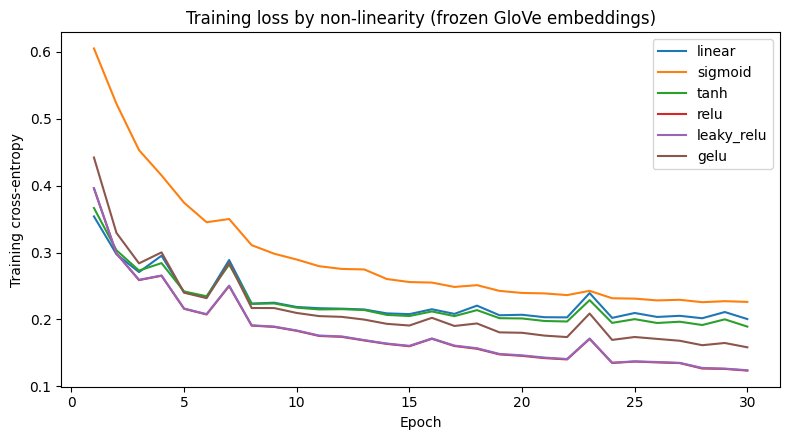

In [13]:
# 4E.2 Training curves (cross-entropy on the training set)

plt.figure(figsize=(8, 4.5))
for act, history in nn_frozen_curves.items():
    plt.plot(range(1, len(history) + 1), history, label=act)
plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy")
plt.title("Training loss by non-linearity (frozen GloVe embeddings)")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# 4E.3 Why the linear network is just a linear model: collapse W and u into one weight vector

linear_net = nn_frozen_models["linear"]
w_collapsed = linear_net.W.T @ linear_net.u          # u^T (W x + b) = (W^T u)^T x + u^T b
c_collapsed = linear_net.u @ linear_net.b

X_test_nn = A_nn_test @ linear_net.L
network_scores = linear_net.forward(A_nn_test)[-1]
collapsed_scores = sigmoid(X_test_nn @ w_collapsed + c_collapsed)

print("Hidden units in the network:", linear_net.W.shape[0])
print("Max difference between network and single linear model:", np.abs(network_scores - collapsed_scores).max())
print("Identical predictions:", np.array_equal(network_scores > 0.5, collapsed_scores > 0.5))

Hidden units in the network: 100
Max difference between network and single linear model: 8.326672684688674e-16
Identical predictions: True


**Reading 4D–4E.**

- **The gradients are correct.** Every hand-derived gradient matches its numerical estimate to within about $10^{-6}$ relative error (most around $10^{-8}$), for all six activations and for $W$, $b$, $u$ and the embeddings $L$.
- **No non-linearity = linear model.** Cell 4E.3 shows the 100-unit `linear` network reduces exactly to one weight vector $w = W^Tu$, as the lecture says ($W_1W_2x = Wx$). Its test F1 (0.916) is close to GloVe + logistic regression (0.904); the small gap comes from training (SGD, different regularisation, training-vocabulary features), not from extra capacity.
- **Non-linearity helps in-domain.** ReLU and Leaky ReLU reach about 0.954 test F1, roughly +4 points over the linear network with the *same* frozen GloVe features. They also reach the lowest training loss (see the curves in 4E.2), consistent with the lecture's point that ReLU trains well because of good gradient flow. Sigmoid is the weakest (0.902): it saturates, and its derivative is at most 0.25, so gradients shrink.
- **But not out-of-domain.** On our real ads, the non-linear networks do *not* improve; ReLU is lower than the linear network (0.40 vs 0.48). A more flexible decision boundary fits the dark-patterns domain more closely, which doesn't transfer to differently written ads. ReLU does improve hard-negative accuracy (0.74 vs 0.66).

## Experiment 4F — Learning the word vectors too

The lecture stresses that a neural classifier learns **both $W$ and the word representations**: in deep learning, θ includes the word vectors.
We now also update the embedding matrix $L$ with the gradient $\partial J/\partial L$ derived in 4C (checked in 4D). The GloVe vectors are only the starting point; backprop moves them to make the classes easier to separate.

In [15]:
# 4F.1 Same grid, but the embedding matrix L is updated as well

nn_finetuned_results, nn_finetuned_curves, nn_finetuned_models = run_activation_grid(finetune=True)
display(nn_finetuned_results.style.format(metric_format))

frozen_vs_finetuned = pd.DataFrame({
    "Activation": nn_frozen_results["Activation"],
    "Test F1 — frozen": nn_frozen_results["Test F1"],
    "Test F1 — fine-tuned": nn_finetuned_results["Test F1"],
    "Real ads F1 — frozen": nn_frozen_results["Real ads F1"],
    "Real ads F1 — fine-tuned": nn_finetuned_results["Real ads F1"],
})
print("Frozen vs. fine-tuned embeddings:")
display(frozen_vs_finetuned.style.format({c: "{:.3f}" for c in frozen_vs_finetuned.columns if c != "Activation"}))

,Activation,Test F1,Real ads F1,Synthetic F1,Hard-negative accuracy,Final train loss,Test F1 std
0,linear,0.904,0.493,0.416,0.737,0.105,0.003
1,sigmoid,0.888,0.488,0.430,0.674,0.167,0.004
2,tanh,0.905,0.490,0.413,0.748,0.105,0.001
3,relu,0.919,0.520,0.401,0.778,0.076,0.005
4,leaky_relu,0.920,0.507,0.402,0.778,0.077,0.002
5,gelu,0.909,0.477,0.397,0.756,0.095,0.006


Frozen vs. fine-tuned embeddings:


,Activation,Test F1 — frozen,Test F1 — fine-tuned,Real ads F1 — frozen,Real ads F1 — fine-tuned
0,linear,0.880,0.904,0.461,0.493
1,sigmoid,0.878,0.888,0.478,0.488
2,tanh,0.884,0.905,0.417,0.490
3,relu,0.910,0.919,0.436,0.520
4,leaky_relu,0.910,0.920,0.436,0.507
5,gelu,0.892,0.909,0.419,0.477


In [16]:
# 4F.2 How did backprop move the word vectors?

tuned_L = nn_finetuned_models["relu"].L
displacement = np.linalg.norm(tuned_L - L_init, axis=1)
from_glove = np.abs(L_init).sum(axis=1) > 0
word_counts = np.asarray((A_nn_train > 0).sum(axis=0)).ravel()

def cosine_to_init(i):
    a, b = L_init[i], tuned_L[i]
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-8)) if from_glove[i] else np.nan

def nearest_in_vocab(L, i, topn=5):
    norms = np.linalg.norm(L, axis=1) + 1e-8
    sims = (L @ L[i]) / (norms * norms[i])
    sims[i] = -np.inf
    return ", ".join(nn_index_to_word[np.argsort(-sims)[:topn]])

print(f"Median vector change — GloVe-initialised words: {np.median(displacement[from_glove]):.3f}")
print(f"Median vector change — words learned from zero: {np.median(displacement[~from_glove]):.3f}")
print(f"Median GloVe vector norm (for scale): {np.median(np.linalg.norm(L_init[from_glove], axis=1)):.3f}")

top_moved = np.argsort(-displacement)[:12]
display(pd.DataFrame({
    "word": nn_index_to_word[top_moved],
    "texts containing it": word_counts[top_moved],
    "initialised from GloVe": from_glove[top_moved],
    "change (L2)": displacement[top_moved],
    "cosine to GloVe init": [cosine_to_init(i) for i in top_moved],
    "neighbours after fine-tuning": [nearest_in_vocab(tuned_L, i) for i in top_moved],
}).style.format({"change (L2)": "{:.3f}", "cosine to GloVe init": "{:.3f}"}))

Median vector change — GloVe-initialised words: 0.007
Median vector change — words learned from zero: 0.009
Median GloVe vector norm (for scale): 5.357


,word,texts containing it,initialised from GloVe,change (L2),cosine to GloVe init,neighbours after fine-tuning
0,all,58,True,0.642,0.994,"those, these, other, some, well"
1,bought,61,True,0.507,0.996,"purchased, sold, sell, buy, purchase"
2,no,114,True,0.468,0.997,"there, any, not, only, without"
3,sold,16,True,0.451,0.997,"bought, purchased, sell, selling, sale"
4,thanks,86,True,0.436,0.996,"coming, good, advantage, strong, better"
5,just,51,True,0.422,0.997,"going, so, only, now, even"
6,our,40,True,0.421,0.998,"my, their, your, own, we"
7,limited,79,True,0.403,0.997,"extended, provided, only, full, however"
8,selling,7,True,0.391,0.998,"buying, sell, sold, buy, sales"
9,purchased,67,True,0.390,0.997,"bought, sold, purchase, sell, buy"


**Reading 4F.** Updating the word vectors improves every activation on the test set (ReLU 0.954 → **0.965**, the best result in the project so far), and also on our real ads (ReLU 0.40 → 0.45, linear and tanh ≈ 0.51).

Most vectors barely move (median change ≈ 0.007, while a typical GloVe vector has length ≈ 5), and even the most-changed words keep a cosine above 0.99 to their starting point. The largest changes go to frequent, class-informative words: *no* and *thanks* (confirmshaming: "No thanks, …"), *limited*, *bought / purchased / sold* (activity notifications), and *all* (neutral navigation such as "Shop all"). Words GloVe does not know, such as *don't*, start at zero and are learned entirely through backprop. This is what the lecture means by the network "moving word vectors around" so the classes become easier to separate with the final linear layer.

The risk is the same as in 4E: fine-tuning adapts the vectors to the dark-patterns domain. With about 1,900 training texts, the vectors are pushed toward this domain's templates; synthetic-set F1 drops slightly (≈0.40 → 0.38).

## Experiment 4 — Comparison with Experiments 1–3

**Test F1** is measured on the same held-out test set for every model. For the external sets, note one difference: the logistic-regression rows come from Experiment 3, where the final models were retrained on the *full* main dataset, while the neural networks here were trained on the training split only (about 80% of the data). If anything, this slightly favours the earlier models on the external sets.

In [17]:
# 4G.1 Overall comparison

best = lambda table, act: table.loc[table["Activation"] == act].iloc[0]
nn_rows = []
for label, table in [("NN (ReLU) — frozen GloVe", nn_frozen_results),
                     ("NN (ReLU) — fine-tuned embeddings", nn_finetuned_results),
                     ("NN (linear, no non-linearity) — frozen GloVe", nn_frozen_results)]:
    act = "linear" if "linear" in label else "relu"
    r = best(table, act)
    nn_rows.append({
        "Model": label,
        "Test F1": r["Test F1"],
        "Real ads F1": r["Real ads F1"],
        "Synthetic F1": r["Synthetic F1"],
        "Hard-negative accuracy": r["Hard-negative accuracy"],
    })

prev_rows = []
for _, r in comparison_external.iterrows():
    rep = r["Representation"]
    prev_rows.append({
        "Model": f"{rep} + logistic regression",
        "Test F1": comparison_test.loc[comparison_test["Representation"] == rep, "Binary F1"].iloc[0],
        "Real ads F1": r["Real ads F1"],
        "Synthetic F1": r["Synthetic (all) F1"],
        "Hard-negative accuracy": r["Synthetic hard negatives accuracy"],
    })

overall_comparison = pd.DataFrame(prev_rows + nn_rows)
display(overall_comparison.style.format({c: "{:.3f}" for c in overall_comparison.columns if c != "Model"}))

,Model,Test F1,Real ads F1,Synthetic F1,Hard-negative accuracy
0,TF-IDF + logistic regression,0.943,0.468,0.414,0.822
1,Word2Vec — project corpus + logistic regression,0.921,0.571,0.498,0.778
2,Pretrained GloVe + logistic regression,0.866,0.415,0.404,0.800
3,NN (ReLU) — frozen GloVe,0.910,0.436,0.387,0.774
4,NN (ReLU) — fine-tuned embeddings,0.919,0.520,0.401,0.778
5,"NN (linear, no non-linearity) — frozen GloVe",0.880,0.461,0.429,0.726


In [18]:
# 4G.2 Save the overall comparison

save_table(overall_comparison, "exp4_overall_comparison")
print("Saved to results/.")

Saved to results/.


# Experiment 4 — Summary

| Model (same test split) | Test F1 | Real ads F1 |
|---|---|---|
| GloVe + logistic regression (Exp. 3) | 0.904 | 0.415 |
| NN, no non-linearity, frozen GloVe | 0.916 | 0.481 |
| NN, ReLU, frozen GloVe | 0.954 | 0.404 |
| NN, ReLU, fine-tuned embeddings | **0.965** | 0.453 |
| Word2Vec + logistic regression (Exp. 3) | 0.940 | **0.571** |

**What the lecture predicts, and what we observed**

1. *Backprop is the chain rule plus reuse of the upstream gradient.* The toy computation graph (4B) reproduces the lecture's numbers, and the hand-derived gradients of the full network pass a numerical check (4D).
2. *Without non-linearities, depth adds nothing.* The linear network collapses exactly to one linear classifier (4E.3) and performs like logistic regression.
3. *Non-linearities give a more flexible classifier.* ReLU adds about 4 F1 points in-domain over the same features and reaches the lowest training loss; sigmoid is the weakest.
4. *A neural classifier learns the representations too.* Fine-tuning the word vectors gives the best in-domain result of the whole project.

**What this means for our research question.** The neural network is the strongest model *inside* the dark-patterns domain, but the extra flexibility does not transfer to our own ads. The best external result is still the simple Word2Vec + logistic regression model from Experiment 3. The bottleneck is not model capacity but the gap between the training data (website UI text) and the target data (advertising copy with fear, exaggeration, authority).

**Limitations.** Hyperparameters (100 hidden units, learning rate 0.1, 30 epochs) were fixed, not tuned on a validation set. Results are averaged over 3 seeds on one split rather than cross-validated. The real-ads set has 57 examples, so differences of a few F1 points there are within noise.